# 🩺 Diabetes Diagnosis — K-Nearest Neighbors (KNN) Classification
**Medical Diagnostic Prediction Using the Pima Indians Diabetes Dataset**

This notebook develops an end-to-end medical classification pipeline predicting diabetes onset (`Outcome = 1`) versus non-diabetic (`Outcome = 0`) based on diagnostic measurements.

### 📋 Key Workflow Stages:
1. **Data Ingestion & Structural Inspection**
2. **Biological Zero-Handling (Hidden Missing Values)**: Handling zeros in Insulin, SkinThickness, Glucose, BloodPressure, and BMI.
3. **Exploratory Data Analysis (EDA)**: Class imbalance audit, feature distributions, and correlation heatmap.
4. **Data Preprocessing**: Stratified train-test partitioning and feature scaling.
5. **Model Building & K-Tuning**: Evaluating $K \in [1, 21]$ to maximize diagnostic recall and accuracy.
6. **Clinical Evaluation**: Confusion matrix analysis, precision, recall, F1-score, and classification report.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## 1. Data Ingestion & Structural Audit

In [2]:
df = pd.read_csv("diabetes.csv")
print(f"Dataset loaded: {df.shape[0]} patients x {df.shape[1]} clinical features\n")
display(df.head())
print("\nDataset Info:")
df.info()


Dataset loaded: 768 patients x 9 clinical features



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


## 2. Biological Zero-Value Inspection & Imputation
In clinical datasets, zero measurements for metrics such as **Glucose**, **BloodPressure**, **SkinThickness**, **Insulin**, and **BMI** are physiologically impossible and indicate missing values encoded as zeros.


In [3]:
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zero_counts = {col: (df[col] == 0).sum() for col in zero_cols}
zero_pcts = {col: ((df[col] == 0).sum() / len(df)) * 100 for col in zero_cols}

zero_df = pd.DataFrame({'Missing (Zeros)': zero_counts, 'Percentage (%)': zero_pcts})
print("Missing Clinical Values Encoded as 0:")
display(zero_df.round(2))

# Impute missing values with median grouped by Outcome to preserve class distributions
df_imputed = df.copy()
for col in zero_cols:
    df_imputed[col] = df_imputed[col].replace(0, np.nan)
    df_imputed[col] = df_imputed.groupby('Outcome')[col].transform(lambda x: x.fillna(x.median()))

print("Verification: Missing values remaining after class-conditioned median imputation:")
print(df_imputed.isna().sum())


Missing Clinical Values Encoded as 0:


,Missing (Zeros),Percentage (%)
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


Verification: Missing values remaining after class-conditioned median imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


## 3. Exploratory Data Analysis & Target Distribution

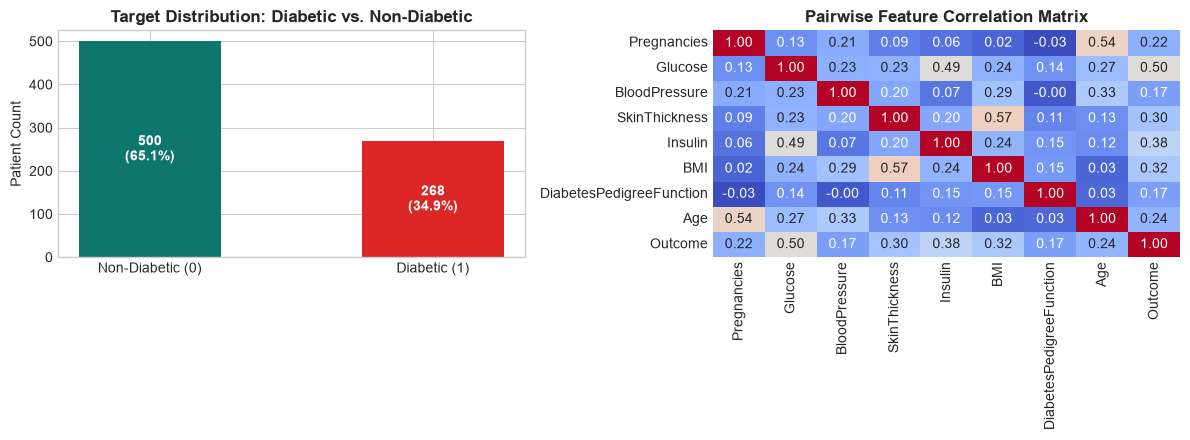

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)

# Target Distribution
counts = df_imputed['Outcome'].value_counts()
axes[0].bar(['Non-Diabetic (0)', 'Diabetic (1)'], counts.values, color=['#0F766E', '#DC2626'], width=0.5)
axes[0].set_title("Target Distribution: Diabetic vs. Non-Diabetic", fontweight='bold')
axes[0].set_ylabel("Patient Count")
for i, v in enumerate(counts.values):
    axes[0].text(i, v / 2, f"{v}\n({(v/len(df_imputed))*100:.1f}%)", ha='center', va='center', color='white', fontweight='bold')

# Correlation Matrix
corr = df_imputed.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1], cbar=False)
axes[1].set_title("Pairwise Feature Correlation Matrix", fontweight='bold')

plt.tight_layout()
plt.show()


## 4. Bivariate Clinical Predictor Distributions

C:\Users\arjun\AppData\Local\Temp\ipykernel_21008\3966267617.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_imputed, x='Outcome', y='Glucose', palette=['#0F766E', '#DC2626'], ax=axes[0])
C:\Users\arjun\AppData\Local\Temp\ipykernel_21008\3966267617.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Non-Diabetic (0)', 'Diabetic (1)'])
C:\Users\arjun\AppData\Local\Temp\ipykernel_21008\3966267617.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_imputed, x='Outcome', y='BMI', palette=['#0F766E', '#DC2626'], ax=axes[1])
C:\User

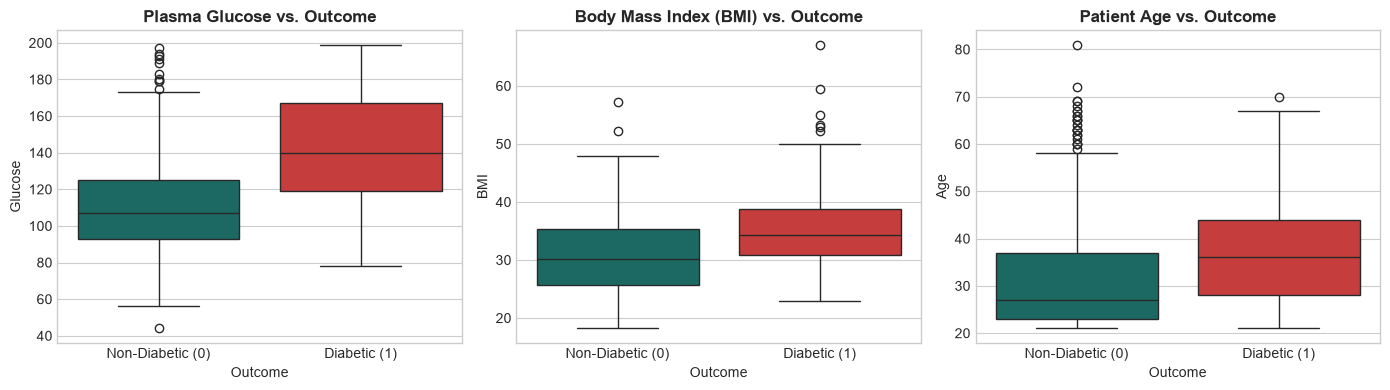

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), dpi=100)

sns.boxplot(data=df_imputed, x='Outcome', y='Glucose', palette=['#0F766E', '#DC2626'], ax=axes[0])
axes[0].set_title("Plasma Glucose vs. Outcome", fontweight='bold')
axes[0].set_xticklabels(['Non-Diabetic (0)', 'Diabetic (1)'])

sns.boxplot(data=df_imputed, x='Outcome', y='BMI', palette=['#0F766E', '#DC2626'], ax=axes[1])
axes[1].set_title("Body Mass Index (BMI) vs. Outcome", fontweight='bold')
axes[1].set_xticklabels(['Non-Diabetic (0)', 'Diabetic (1)'])

sns.boxplot(data=df_imputed, x='Outcome', y='Age', palette=['#0F766E', '#DC2626'], ax=axes[2])
axes[2].set_title("Patient Age vs. Outcome", fontweight='bold')
axes[2].set_xticklabels(['Non-Diabetic (0)', 'Diabetic (1)'])

plt.tight_layout()
plt.show()


## 5. Feature Matrix Preparation, Train-Test Split & Scaling

In [6]:
X = df_imputed.drop(columns=['Outcome'])
y = df_imputed['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train Shape: {X_train.shape} | X_test Shape: {X_test.shape}")
print(f"Diabetic prevalence in train set: {y_train.mean()*100:.1f}%")
print(f"Diabetic prevalence in test set:  {y_test.mean()*100:.1f}%")


X_train Shape: (576, 8) | X_test Shape: (192, 8)
Diabetic prevalence in train set: 34.9%
Diabetic prevalence in test set:  34.9%


## 6. KNN Model Optimization & K-Tuning

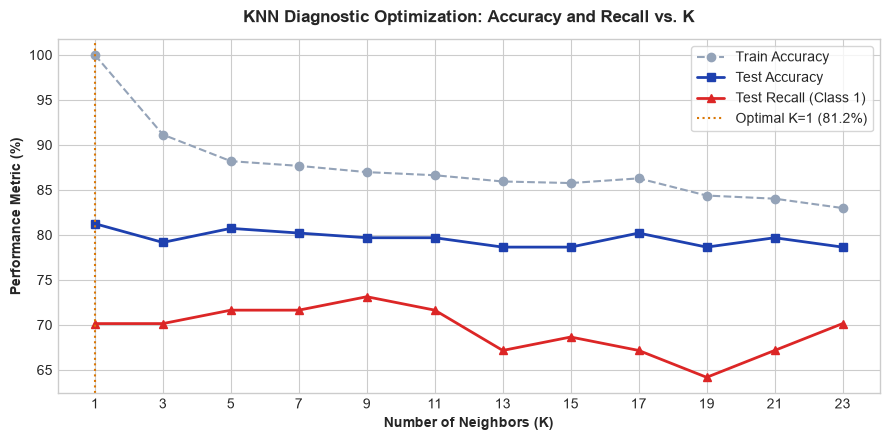

In [7]:
k_values = list(range(1, 25, 2))
train_scores = []
test_scores = []
recall_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn.fit(X_train_scaled, y_train)
    y_pred_te = knn.predict(X_test_scaled)
    train_scores.append(accuracy_score(y_train, knn.predict(X_train_scaled)))
    test_scores.append(accuracy_score(y_test, y_pred_te))
    recall_scores.append(recall_score(y_test, y_pred_te))

plt.figure(figsize=(9, 4.5), dpi=100)
plt.plot(k_values, [s * 100 for s in train_scores], 'o--', color='#94A3B8', label='Train Accuracy')
plt.plot(k_values, [s * 100 for s in test_scores], 's-', color='#1E40AF', label='Test Accuracy', lw=2)
plt.plot(k_values, [s * 100 for s in recall_scores], '^-', color='#DC2626', label='Test Recall (Class 1)', lw=2)

best_k_idx = np.argmax(test_scores)
optimal_k = k_values[best_k_idx]
plt.axvline(optimal_k, color='#D97706', linestyle=':', label=f'Optimal K={optimal_k} ({test_scores[best_k_idx]*100:.1f}%)')

plt.title("KNN Diagnostic Optimization: Accuracy and Recall vs. K", fontweight='bold', fontsize=12, pad=12)
plt.xlabel("Number of Neighbors (K)", fontweight='bold')
plt.ylabel("Performance Metric (%)", fontweight='bold')
plt.xticks(k_values)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

# Final Model Training
best_knn = KNeighborsClassifier(n_neighbors=optimal_k, metric='euclidean')
best_knn.fit(X_train_scaled, y_train)
y_pred = best_knn.predict(X_test_scaled)
y_proba = best_knn.predict_proba(X_test_scaled)[:, 1]


## 7. Model Evaluation & Clinical Interpretation
In clinical diagnostic screening, **Recall / Sensitivity** (minimizing False Negatives) is paramount because failing to identify a diabetic patient leads to untreated complications.


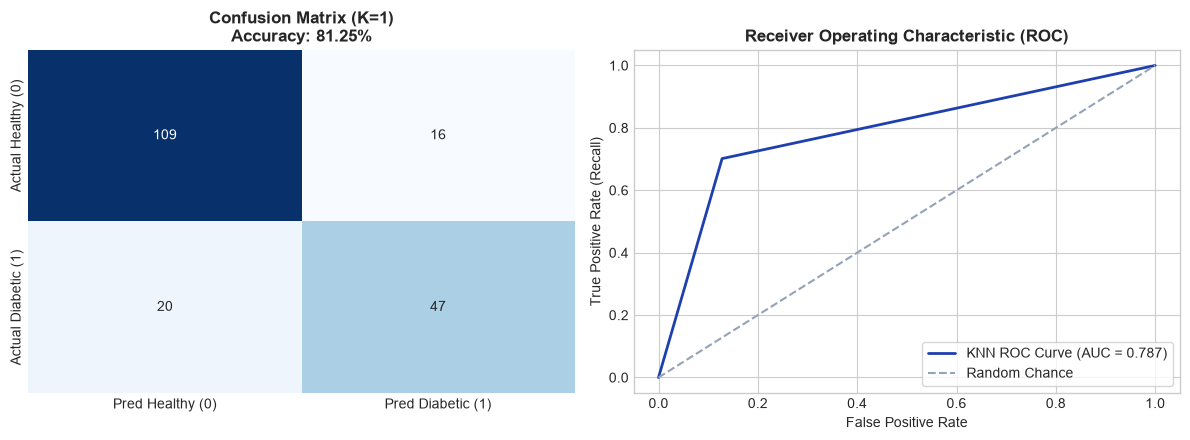

CLINICAL EVALUATION CLASSIFICATION REPORT
                  precision    recall  f1-score   support

Non-Diabetic (0)       0.84      0.87      0.86       125
    Diabetic (1)       0.75      0.70      0.72        67

        accuracy                           0.81       192
       macro avg       0.80      0.79      0.79       192
    weighted avg       0.81      0.81      0.81       192

ROC-AUC Score: 0.7867


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Pred Healthy (0)', 'Pred Diabetic (1)'],
            yticklabels=['Actual Healthy (0)', 'Actual Diabetic (1)'])
axes[0].set_title(f"Confusion Matrix (K={optimal_k})\nAccuracy: {accuracy_score(y_test, y_pred)*100:.2f}%", fontweight='bold')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc_val = roc_auc_score(y_test, y_proba)
axes[1].plot(fpr, tpr, color='#1E40AF', lw=2, label=f'KNN ROC Curve (AUC = {auc_val:.3f})')
axes[1].plot([0, 1], [0, 1], color='#94A3B8', linestyle='--', label='Random Chance')
axes[1].set_title("Receiver Operating Characteristic (ROC)", fontweight='bold')
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

print("=" * 60)
print("CLINICAL EVALUATION CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=['Non-Diabetic (0)', 'Diabetic (1)']))
print(f"ROC-AUC Score: {auc_val:.4f}")
